<a href="https://colab.research.google.com/github/pranathiperii/alphagenome_endometriosis/blob/main/alphagenome_endometriosis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# What do endometriosis GWAS risk variants do? Sequence-based prediction with AlphaGenome

**Question.** GWAS has found endometriosis risk loci, but not what the risk variants do. For each variant, AlphaGenome compares the reference and alternative DNA sequence and predicts changes in gene expression, splicing and local regulatory signals across thousands of tissue and assay tracks.

**Variants:** the replicated loci from Rahmioglu et al. 2014 (*Human Reproduction*), plus rs3820282, the fine-mapped candidate at WNT4.

## 1. Install and connect
Store your key in Colab secrets as `ALPHAGENOME_API_KEY` (key icon, left sidebar).

In [2]:
!pip install -q alphagenome==0.7.0
import time, requests, numpy as np, pandas as pd
from alphagenome.data import genome
from alphagenome.models import dna_client, variant_scorers
from google.colab import userdata
model = dna_client.create(userdata.get('ALPHAGENOME_API_KEY'))
import os; os.makedirs('results', exist_ok=True)

## 2. Variants: positions and alleles from Ensembl (GRCh38), never typed by hand
`risk` holds the endometriosis risk allele from Rahmioglu 2014 (Table II); for rs3820282 it is T, the allele that creates an oestrogen-receptor binding site (Pavličev et al. 2024). Risk alleles for the four extra loci are left blank: their scores are used for ranking only.

In [3]:
snps = {
    'rs7521902':  ('WNT4 (lead)',        'A'),
    'rs3820282':  ('WNT4 (fine-mapped)', 'T'),
    'rs13394619': ('GREB1',              'G'),
    'rs10859871': ('VEZT',               'C'),
    'rs1250248':  ('FN1',                'A'),
    'rs12700667': ('7p15.2',             None),
    'rs1537377':  ('CDKN2B-AS1',         None),
    'rs7739264':  ('ID4',                None),
    'rs4141819':  ('2p14',               None),
}
alt_override = {'rs3820282': 'T'}   # multi-allelic: score the allele of interest

def ensembl(rsid, tries=5):
    for i in range(tries):
        r = requests.get(f'https://rest.ensembl.org/variation/human/{rsid}', headers={'Content-Type': 'application/json'})
        if r.ok:
            m = [x for x in r.json()['mappings'] if x['assembly_name'] == 'GRCh38'][0]
            alleles = m['allele_string'].split('/')            # first = reference (forward strand)
            return {'chrom': 'chr' + m['seq_region_name'], 'pos': m['start'], 'ref': alleles[0], 'alts': alleles[1:]}
        time.sleep(2 * (i + 1))
    r.raise_for_status()

rows = []
for rsid, (label, risk) in snps.items():
    e = ensembl(rsid); time.sleep(0.3)
    alt = alt_override.get(rsid, e['alts'][0])
    sign = 1 if risk == alt else (-1 if risk == e['ref'] else np.nan)   # +1: alt is the risk allele; -1: flip
    rows.append({'rsid': rsid, 'label': label, **{k: e[k] for k in ['chrom', 'pos', 'ref']}, 'alt': alt, 'risk_allele': risk, 'risk_sign': sign})
variants = pd.DataFrame(rows)
variants.to_csv('results/variants.csv', index=False)
variants      # CHECK positions before scoring

,rsid,label,chrom,pos,ref,alt,risk_allele,risk_sign
0,rs7521902,WNT4 (lead),chr1,22164231,C,A,A,1.0
1,rs3820282,WNT4 (fine-mapped),chr1,22141722,C,T,T,1.0
2,rs13394619,GREB1,chr2,11587381,G,A,G,-1.0
3,rs10859871,VEZT,chr12,95318100,A,C,C,1.0
4,rs1250248,FN1,chr2,215422370,A,G,A,-1.0
5,rs12700667,7p15.2,chr7,25862019,G,A,NaN,NaN
6,rs1537377,CDKN2B-AS1,chr9,22169701,T,C,NaN,NaN
7,rs7739264,ID4,chr6,19785357,C,A,NaN,NaN
8,rs4141819,2p14,chr2,67637543,C,G,NaN,NaN


## 3. Score each variant in a 1 Mb window
A 1 Mb window lets the model see genes up to about 500 kb either side (a 16 kb window sees only about 8 kb).

In [4]:
scorers = list(variant_scorers.RECOMMENDED_VARIANT_SCORERS.values())
out = []
for _, v in variants.iterrows():
    var = genome.Variant(chromosome=v.chrom, position=int(v.pos), reference_bases=v.ref, alternate_bases=v.alt)
    interval = var.reference_interval.resize(dna_client.SEQUENCE_LENGTH_1MB)
    df = variant_scorers.tidy_scores(model.score_variant(interval=interval, variant=var, variant_scorers=scorers))
    df['rsid'], df['label'] = v.rsid, v.label
    out.append(df); print('scored', v.rsid, df.shape)
scores = pd.concat(out, ignore_index=True)
scores['scorer'] = scores['variant_scorer'].astype(str).str.extract(r'^(\w+)')[0]
scores['assay'] = scores['variant_scorer'].astype(str).str.extract(r'requested_output=(\w+)')[0]
scores.to_csv('results/alphagenome_1Mb_scores.csv.gz', index=False)
scores.shape

scored rs7521902 (34266, 27)
scored rs3820282 (37575, 27)
scored rs13394619 (31288, 27)
scored rs10859871 (29814, 27)
scored rs1250248 (33402, 27)
scored rs12700667 (22394, 27)
scored rs1537377 (21652, 27)
scored rs7739264 (17200, 27)
scored rs4141819 (18684, 27)


(246275, 29)

## 4. Which variants stand out? Count extreme tracks, compared with chance
Each variant is scored on thousands of expression tracks, so its single top score is near 1 by chance. Instead, count tracks with |quantile| > 0.999; by chance, about 1 in 1,000 tracks passes.

In [5]:
lfc = scores[scores['scorer'] == 'GeneMaskLFCScorer'].copy()
lfc['abs_q'] = lfc['quantile_score'].abs()
rank = (lfc.groupby(['rsid', 'label'])
          .agg(tracks=('abs_q', 'size'), extreme=('abs_q', lambda q: int((q > 0.999).sum())),
               max_raw_lfc=('raw_score', lambda x: round(x.abs().max(), 3)))
          .reset_index())
rank['expected_by_chance'] = (rank['tracks'] * 0.001).round(1)
rank['fold_over_chance'] = (rank['extreme'] / rank['expected_by_chance']).round(1)
rank = rank.sort_values('extreme', ascending=False)
rank.to_csv('results/extreme_track_counts.csv', index=False)
rank

,rsid,label,tracks,extreme,max_raw_lfc,expected_by_chance,fold_over_chance
5,rs3820282,WNT4 (fine-mapped),13356,132,0.098,13.4,9.9
1,rs1250248,FN1,7049,10,0.064,7.0,1.4
7,rs7521902,WNT4 (lead),13356,2,0.029,13.4,0.1
2,rs12700667,7p15.2,7420,1,0.018,7.4,0.1
0,rs10859871,VEZT,11130,0,0.015,11.1,0.0
4,rs1537377,CDKN2B-AS1,7049,0,0.011,7.0,0.0
3,rs13394619,GREB1,11130,0,0.010,11.1,0.0
6,rs4141819,2p14,5565,0,0.008,5.6,0.0
8,rs7739264,ID4,4823,0,0.010,4.8,0.0


## 5. Reproductive tissues: direction for the risk allele
`risk_lfc` = predicted change for the **risk** allele (the sign is flipped where the risk allele is the reference).

In [6]:
targets = {'rs7521902': 'WNT4', 'rs3820282': 'WNT4', 'rs13394619': 'GREB1', 'rs10859871': 'VEZT', 'rs1250248': 'FN1'}
repro = 'uter|endometri|ovar|myometr|fallopian|vagin'
sign = variants.set_index('rsid')['risk_sign']
r = lfc[lfc['biosample_name'].astype(str).str.contains(repro, case=False)].copy()
r = r[[targets.get(s) == g for s, g in zip(r['rsid'], r['gene_name'])]]
r['risk_lfc'] = r['raw_score'] * r['rsid'].map(sign)
repro_tab = r[['label', 'gene_name', 'biosample_name', 'risk_lfc', 'quantile_score']].sort_values(['label', 'biosample_name'])
repro_tab.to_csv('results/reproductive_tissue_effects.csv', index=False)
repro_tab.round(4)

,label,gene_name,biosample_name,risk_lfc,quantile_score
137080,FN1,FN1,fallopian tube,0.0047,-0.9674
136786,FN1,FN1,myometrial cell,0.0025,-0.9179
137054,FN1,FN1,outer medulla of kidney,-0.0002,0.2167
136919,FN1,FN1,ovary,0.0025,-0.8902
136920,FN1,FN1,ovary,0.0029,-0.9325
137043,FN1,FN1,ovary,0.0034,-0.9255
136811,FN1,FN1,uterine smooth muscle cell,0.0032,-0.9545
136921,FN1,FN1,uterus,0.0050,-0.9854
137044,FN1,FN1,uterus,0.0054,-0.9802
136922,FN1,FN1,vagina,0.0053,-0.9854


## 6. GREB1: is the strongest splicing change at the variant itself?
rs13394619 is annotated as the last base of a GREB1 intron (splice acceptor). If the model's top junctions end at the variant's position, the prediction sits exactly where the biology says it should.

In [7]:
g = variants.set_index('rsid').loc['rs13394619']
sj = scores[(scores['rsid'] == 'rs13394619') & scores['junction_End'].notna()].copy()
sj['abs_q'] = sj['quantile_score'].abs()
top_sj = sj.sort_values('abs_q', ascending=False).head(10)[['biosample_name', 'junction_Start', 'junction_End', 'raw_score', 'quantile_score']]
print('Variant position:', g.pos)
print('Top junctions ending at the variant:', int((top_sj['junction_End'] == g.pos).sum()), 'of 10')
top_sj.to_csv('results/greb1_top_junctions.csv', index=False)
top_sj

Variant position: 11587381
Top junctions ending at the variant: 10 of 10


,biosample_name,junction_Start,junction_End,raw_score,quantile_score
98694,progenitor cell of endocrine pancreas,11585905,11587381,1.278320,0.999817
98756,HepG2,11585905,11587381,1.199219,0.999817
98757,HepG2,11585905,11587381,1.065430,0.999790
98577,adrenal gland,11580832,11587381,1.349609,0.999790
98472,testis,11580832,11587381,1.176758,0.999783
98578,adrenal gland,11580832,11587381,1.275391,0.999776
98945,adrenal gland,11585905,11587381,1.280273,0.999776
98944,adrenal gland,11585905,11587381,1.287109,0.999768
98389,HepG2,11580832,11587381,1.072266,0.999768
98943,adrenal gland,11585905,11587381,0.987305,0.999768


## 7. WNT4 rs3820282: oestrogen-receptor binding at the variant
The knock-in study showed T creates a high-affinity ERα site. Does the model predict more ESR1 binding?

In [8]:
tf = scores[(scores['rsid'] == 'rs3820282') & (scores['assay'] == 'CHIP_TF') & (scores['scorer'] == 'CenterMaskScorer')]
esr = tf[tf['transcription_factor'].astype(str).str.upper().isin(['ESR1', 'FOXA1', 'GATA3'])]
esr[['transcription_factor', 'biosample_name', 'raw_score', 'quantile_score']].sort_values('quantile_score', ascending=False)

,transcription_factor,biosample_name,raw_score,quantile_score
69334,ESR1,MCF-7,495.000000,0.958945
69341,GATA3,MCF-7,496.500000,0.946842
68625,GATA3,A549,453.000000,0.935631
68852,FOXA1,HepG2,539.500000,0.917249
69338,FOXA1,MCF-7,500.500000,0.914641
68851,FOXA1,HepG2,395.500000,0.900452
35926,GATA3,SH-SY5Y,0.050562,0.890222
35554,FOXA1,MCF-7,0.040848,0.875283
35550,ESR1,MCF-7,0.024938,0.823916
69951,GATA3,SK-N-SH,258.500000,0.616409


## 8. VEZT: was the gene inside the window?
rs10859871 lies about 17 kb from VEZT, outside a 16 kb window (about 8 kb each side) but inside 1 Mb.

In [9]:
vz = lfc[(lfc['rsid'] == 'rs10859871') & (lfc['gene_name'].isin(['VEZT', 'MIR3685']))]
vz.groupby('gene_name').agg(tracks=('raw_score', 'size'), median_risk_lfc=('raw_score', 'median'),
                             share_down=('raw_score', lambda x: round((x < 0).mean(), 2)),
                             extreme=('abs_q', lambda q: int((q > 0.999).sum())))

,tracks,median_risk_lfc,share_down,extreme
gene_name,,,,
MIR3685,371,-0.005010,0.96,0
VEZT,371,-0.001276,0.86,0


## 9. Figures

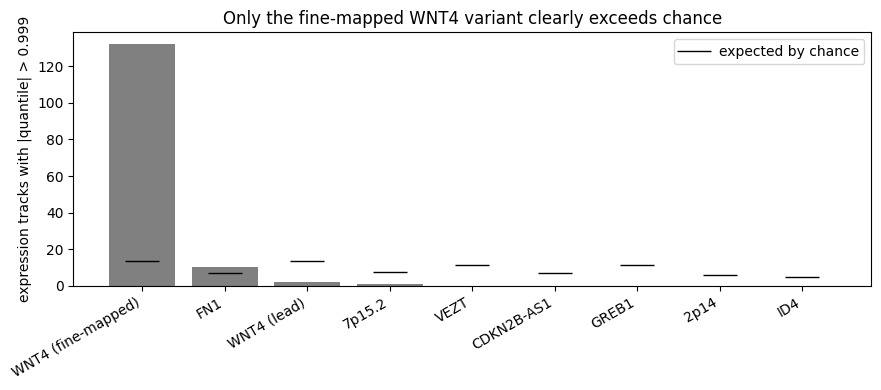

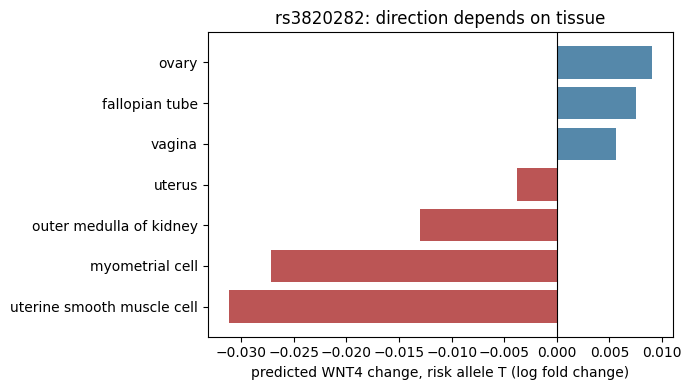

In [10]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(rank['label'], rank['extreme'], color='grey')
ax.plot(rank['label'], rank['expected_by_chance'], 'k_', markersize=25, label='expected by chance')
ax.set_ylabel('expression tracks with |quantile| > 0.999'); ax.legend()
plt.xticks(rotation=30, ha='right'); plt.title('Only the fine-mapped WNT4 variant clearly exceeds chance')
plt.tight_layout(); plt.savefig('results/extreme_tracks.png', dpi=300); plt.show()

w = repro_tab[repro_tab['label'] == 'WNT4 (fine-mapped)'].groupby('biosample_name')['risk_lfc'].mean().sort_values()
fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(w.index, w.values, color=['#b55' if v < 0 else '#58a' for v in w.values]); ax.axvline(0, color='k', lw=0.8)
ax.set_xlabel('predicted WNT4 change, risk allele T (log fold change)'); plt.title('rs3820282: direction depends on tissue')
plt.tight_layout(); plt.savefig('results/wnt4_rs3820282_by_tissue.png', dpi=300); plt.show()

## 10. Save to Google Drive

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
!mkdir -p /content/drive/MyDrive/endometriosis_project/alphagenome
!cp -r results /content/drive/MyDrive/endometriosis_project/alphagenome/
print('Saved')